# FedVocabHAR WISDM Phase 1C

## Full confirmed-cluster utilization and balanced federated replay

Phase 1B validated admission safety and forgetting control but left a substantial gap between direct-fragment replay and the oracle upper bound. Phase 1C changes only how a directly confirmed local cluster is used for learning:

> A direct semantic confirmation labels the complete local candidate fragment, while global vocabulary admission still requires matching confirmations from two distinct clients.

The subject split, confirmation budget, seeds, arrival schedules, admission rule, frozen encoder, and evaluation clients are unchanged from Phase 1B. No cross-client label inheritance is used.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
from collections import defaultdict
import copy, json, math, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project: str = '/content/drive/MyDrive/FedVocabHAR'
    seed: int = 42
    base_subjects: tuple = tuple(range(1635,1642))
    integration_subjects: tuple = tuple(range(1643,1648))
    evaluation_subjects: tuple = tuple(range(1648,1651))
    known_activities: tuple = ('F','G','H','I','K')
    novel_activities: tuple = ('L','M','O','P','Q','S')
    fragments_per_client_activity: int = 2
    max_windows_per_fragment: int = 40
    confirmation_budget: int = 18
    promotion_quorum: int = 2
    local_memory_per_known_class: int = 20
    base_train_per_class: int = 300
    oracle_novel_per_client_class: int = 80
    base_epochs: int = 120
    local_epochs: int = 35
    federated_rounds: int = 3
    learning_rate: float = 0.03
    weight_decay: float = 1e-4
    distillation_temperature: float = 2.0
    distillation_weight: float = 1.0
    seeds: tuple = (11,23,37,51,79)
    arrival_modes: tuple = ('synchronous','staggered')
    max_known_accuracy_drop: float = 0.05
    minimum_vocabulary_coverage: float = 2/3
    minimum_novel_macro_f1: float = 0.50
    minimum_coverage_adjusted_novel_f1: float = 0.35
    balance_target_per_class: int = 80
    calibration_known_fpr: float = 0.05

CFG=Config()
PROJECT=Path(CFG.project)
P0=PROJECT/'artifacts'/'phase0'
P0B=PROJECT/'artifacts'/'phase0b'
OUT=PROJECT/'artifacts'/'phase1c'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz'
MODEL=P0B/'contrastive_encoder.pt'
assert CACHE.exists(),f'Missing Phase Zero cache: {CACHE}'
assert MODEL.exists(),f'Missing Phase Zero-B encoder: {MODEL}'
assert not (set(CFG.integration_subjects)&set(CFG.evaluation_subjects))

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE)
print(json.dumps(asdict(CFG),indent=2))


device: cuda
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "base_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "integration_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647
  ],
  "evaluation_subjects": [
    1648,
    1649,
    1650
  ],
  "known_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "novel_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "fragments_per_client_activity": 2,
  "max_windows_per_fragment": 40,
  "confirmation_budget": 18,
  "promotion_quorum": 2,
  "local_memory_per_known_class": 20,
  "base_train_per_class": 300,
  "oracle_novel_per_client_class": 80,
  "base_epochs": 120,
  "local_epochs": 35,
  "federated_rounds": 3,
  "learning_rate": 0.03,
  "weight_decay": 0.0001,
  "distillation_temperature": 2.0,
  "distillation_weight": 1.0,
  "seeds": [
    11,
    23,
    37,
    51,
    79
  ],
  "arrival_modes": [
    "synchronous",
    "stagge

## Load the fixed representation

The Phase Zero-B encoder remains frozen. Phase 1B changes only the vocabulary head or class prototypes, which isolates the effect of integration and avoids representation drift during this feasibility test.


In [3]:
d=np.load(CACHE)
x=d['x'].astype(np.float32)
subjects=d['subject'].astype(int)
activities=d['activity'].astype(str)
positions=d['position'].astype(np.float32)

class Encoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,z):
        h=self.body(z).squeeze(-1)
        return F.normalize(self.project(h),dim=1)

# Phase Zero-B created this checkpoint inside the same FedVocabHAR project.
# PyTorch 2.6+ defaults to weights_only=True, which rejects the stored NumPy
# normalization arrays. Explicitly permit the trusted project checkpoint.
try:
    checkpoint=torch.load(MODEL,map_location='cpu',weights_only=False)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint=torch.load(MODEL,map_location='cpu')
dim=int(checkpoint['config']['embedding_dim'])
encoder=Encoder(dim).to(DEVICE)
encoder.load_state_dict(checkpoint['state_dict'])
encoder.eval()
channel_mean=np.asarray(checkpoint['channel_mean'],dtype=np.float32)
channel_std=np.asarray(checkpoint['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std

emb=[]
with torch.no_grad():
    for start in range(0,len(xn),512):
        emb.append(encoder(torch.from_numpy(xn[start:start+512]).to(DEVICE)).cpu().numpy())
emb=np.concatenate(emb).astype(np.float32)
print('windows:',x.shape,'embeddings:',emb.shape)
print(pd.crosstab(subjects,activities).to_string())


windows: (19704, 3, 128) embeddings: (19704, 96)
col_0    A    B    C    D    E    F    G    H    I    K    L    M    O    P    Q    R    S
row_0                                                                                     
1635    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1636    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1637   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1638   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1639   138  138  138  138  138  138  138  138  138  138    0  138  138  138  138  138  138
1640   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1641    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1643    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1644    55   55   55   55   55   55   55 

## Locked Phase 1B protocol and complete confirmation fragments

The evaluation subjects remain excluded from normalization, confirmation, training, replay, prototype initialization, and calibration. Two versions of every candidate fragment are retained: the original forty-window diagnostic subset and the complete fragment. Both carry the same directly confirmed semantic label.


In [4]:
known_to_index={a:i for i,a in enumerate(CFG.known_activities)}
novel_to_index={a:len(CFG.known_activities)+i for i,a in enumerate(CFG.novel_activities)}
all_to_index={**known_to_index,**novel_to_index}
index_to_activity={v:k for k,v in all_to_index.items()}

base_mask=np.isin(subjects,CFG.base_subjects)&np.isin(activities,CFG.known_activities)
integration_novel_mask=np.isin(subjects,CFG.integration_subjects)&np.isin(activities,CFG.novel_activities)
eval_known_mask=np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.known_activities)
eval_novel_mask=np.isin(subjects,CFG.evaluation_subjects)&np.isin(activities,CFG.novel_activities)

scaler=StandardScaler().fit(emb[base_mask])
z=scaler.transform(emb).astype(np.float32)

def balanced_indices(mask,label_array,classes,per_class,seed):
    rng=np.random.default_rng(seed);out=[]
    for label in classes:
        idx=np.where(mask&(label_array==label))[0]
        if len(idx)>per_class:idx=rng.choice(idx,per_class,replace=False)
        out.extend(idx.tolist())
    return np.asarray(out,dtype=int)

base_idx=balanced_indices(base_mask,activities,CFG.known_activities,CFG.base_train_per_class,CFG.seed)
eval_known_idx=np.where(eval_known_mask)[0]
eval_novel_idx=np.where(eval_novel_mask)[0]
assert not set(subjects[base_idx])&set(CFG.evaluation_subjects)

def evenly_limit(idx,limit):
    if len(idx)<=limit:return idx
    take=np.linspace(0,len(idx)-1,limit).round().astype(int)
    return idx[take]

def build_confirmation_candidates():
    rows=[];private={};limited_windows={};full_windows={};cid=0
    for subject in CFG.integration_subjects:
        for activity in CFG.novel_activities:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)<CFG.fragments_per_client_activity:continue
            idx=idx[np.argsort(positions[idx])]
            for fragment,full_part in enumerate(np.array_split(idx,CFG.fragments_per_client_activity)):
                if len(full_part)==0:continue
                limited=evenly_limit(full_part,CFG.max_windows_per_fragment)
                candidate_id=f'int_{cid:04d}'
                rows.append({'candidate_id':candidate_id,'subject':int(subject),'fragment':int(fragment),
                             'support':int(len(full_part)),'time_center':float(positions[full_part].mean())})
                private[candidate_id]=str(activity)
                limited_windows[candidate_id]=limited.astype(int)
                full_windows[candidate_id]=full_part.astype(int);cid+=1
    public=pd.DataFrame(rows)
    assert not ({'activity','label','true_activity'}&set(public.columns))
    return public,private,limited_windows,full_windows

candidate_public,confirmation_oracle,candidate_windows_limited,candidate_windows_full=build_confirmation_candidates()
print('base train windows:',len(base_idx),'known evaluation:',len(eval_known_idx),
      'novel evaluation:',len(eval_novel_idx),'confirmation candidates:',len(candidate_public))
print('mean complete candidate support:',candidate_public.support.mean(),
      'limited support:',min(CFG.max_windows_per_fragment,candidate_public.support.mean()))
display(candidate_public.head())


base train windows: 1500 known evaluation: 825 novel evaluation: 995 confirmation candidates: 60
mean complete candidate support: 28.35 limited support: 28.35


,candidate_id,subject,fragment,support,time_center
0,int_0000,1643,0,28,0.248848
1,int_0001,1643,1,27,0.755760
2,int_0002,1643,0,28,0.248848
3,int_0003,1643,1,27,0.755760
4,int_0004,1643,0,28,0.247920


## Unchanged client-stratified agreement admission

The admission scheduler is identical to Phase 1B. A class is promoted only after direct confirmations from two distinct integration clients. The run records both the limited and complete directly confirmed window sets for each promoted activity.


In [5]:
def run_confirmation(seed,arrival_mode):
    rng=np.random.default_rng(seed)
    public=candidate_public.copy()
    public['arrival_round']=0 if arrival_mode=='synchronous' else rng.integers(0,CFG.confirmation_budget,len(public))
    queried=[];direct={};client_counts=defaultdict(int);events=[];clock=0
    while len(queried)<CFG.confirmation_budget:
        eligible=[i for i in range(len(public)) if i not in direct and int(public.iloc[i].arrival_round)<=clock]
        if not eligible:
            remaining=public.loc[[i not in direct for i in range(len(public))],'arrival_round']
            if len(remaining)==0:break
            clock=max(clock+1,int(remaining.min()));continue
        minimum=min(client_counts[int(public.iloc[i].subject)] for i in eligible)
        pool=[i for i in eligible if client_counts[int(public.iloc[i].subject)]==minimum]
        chosen=int(rng.choice(pool));row=public.iloc[chosen]
        label=confirmation_oracle[row.candidate_id]
        direct[chosen]=label;queried.append(chosen);client_counts[int(row.subject)]+=1
        label_subjects={lab:{int(public.iloc[j].subject) for j,v in direct.items() if v==lab}
                        for lab in set(direct.values())}
        promoted={lab for lab,subs in label_subjects.items() if len(subs)>=CFG.promotion_quorum}
        events.append({'step':len(queried),'clock':clock,'candidate_id':row.candidate_id,
                       'subject':int(row.subject),'returned_label':label,
                       'promoted_after_query':label in promoted,'arrival_mode':arrival_mode,'seed':seed})
        clock+=1
    label_subjects={lab:{int(public.iloc[j].subject) for j,v in direct.items() if v==lab}
                    for lab in set(direct.values())}
    promoted={lab for lab,subs in label_subjects.items() if len(subs)>=CFG.promotion_quorum}
    limited=[];full=[]
    for i,label in direct.items():
        if label in promoted:
            cid=public.iloc[i].candidate_id
            limited.extend(candidate_windows_limited[cid].tolist())
            full.extend(candidate_windows_full[cid].tolist())
    return {'public':public,'direct':direct,'promoted':promoted,
            'limited_window_idx':np.asarray(limited,dtype=int),'full_window_idx':np.asarray(full,dtype=int),
            'events':events,
            'single_client_promotions':sum(len(label_subjects[x])<CFG.promotion_quorum for x in promoted)}

pilot=run_confirmation(CFG.seeds[0],'synchronous')
print('pilot promoted:',sorted(pilot['promoted']),'limited/full windows:',
      len(pilot['limited_window_idx']),len(pilot['full_window_idx']))


pilot promoted: ['L', 'P', 'Q', 'S'] limited/full windows: 461 461


## Preregistered Phase 1C integration variants

- **Replay-40:** the Phase 1B replay baseline.
- **Replay-full:** replay using complete directly confirmed local fragments.
- **Balanced replay-full:** equalizes known and promoted-class contributions locally.
- **Imprinted replay:** initializes novel classifier rows from aggregated client centroids, then uses balanced replay.
- **Frozen-known calibrated:** preserves the base classifier rows and calibrates novel logits from client-local known memories.
- **Oracle replay:** unchanged upper bound using all local windows of promoted activities.

All learned variants use local training and sample-weighted FedAvg. Raw windows remain on clients.


In [6]:
class LinearHead(nn.Module):
    def __init__(self,input_dim,n_classes):
        super().__init__();self.fc=nn.Linear(input_dim,n_classes)
    def forward(self,q):return self.fc(q)

def fit_base():
    seed_all(CFG.seed)
    model=LinearHead(z.shape[1],len(CFG.known_activities)).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    tx=torch.from_numpy(z[base_idx]).to(DEVICE)
    ty=torch.tensor([known_to_index[a] for a in activities[base_idx]],dtype=torch.long,device=DEVICE)
    for _ in range(CFG.base_epochs):
        opt.zero_grad();loss=F.cross_entropy(model(tx),ty);loss.backward();opt.step()
    return model.eval()

base_model=fit_base()
with torch.no_grad():
    base_known_pred=base_model(torch.from_numpy(z[eval_known_idx]).to(DEVICE)).argmax(1).cpu().numpy()
base_known_true=np.asarray([known_to_index[a] for a in activities[eval_known_idx]])
BASE_KNOWN_ACCURACY=float(accuracy_score(base_known_true,base_known_pred))
BASE_KNOWN_F1=float(f1_score(base_known_true,base_known_pred,average='macro'))
print('base known accuracy:',BASE_KNOWN_ACCURACY,'macro-F1:',BASE_KNOWN_F1)

def local_memory(subject,seed):
    mask=(subjects==subject)&np.isin(activities,CFG.known_activities)
    return balanced_indices(mask,activities,CFG.known_activities,CFG.local_memory_per_known_class,seed+int(subject))

def client_novel_indices(admission,subject,source='full',seed=0):
    promoted=admission['promoted']
    if source=='oracle':
        mask=(subjects==subject)&np.isin(activities,list(promoted))
        return balanced_indices(mask,activities,sorted(promoted),CFG.oracle_novel_per_client_class,seed+int(subject))
    store=candidate_windows_limited if source=='limited' else candidate_windows_full
    out=[];public=admission['public']
    for i,label in admission['direct'].items():
        row=public.iloc[i]
        if int(row.subject)==int(subject) and label in promoted:out.extend(store[row.candidate_id].tolist())
    return np.asarray(out,dtype=int)

def balance_training_indices(indices,seed):
    rng=np.random.default_rng(seed);labels=activities[indices];present=sorted(set(labels));out=[]
    target=min(CFG.balance_target_per_class,max(np.sum(labels==label) for label in present))
    for label in present:
        q=indices[labels==label]
        out.extend(rng.choice(q,target,replace=len(q)<target).tolist())
    return np.asarray(out,dtype=int)

def aggregate_imprints(admission):
    imprints={};messages=0
    known_scale=float(base_model.fc.weight.norm(dim=1).mean().detach().cpu())
    for label in sorted(admission['promoted']):
        sums=[];counts=[]
        for subject in CFG.integration_subjects:
            idx=client_novel_indices(admission,subject,'full')
            idx=idx[activities[idx]==label]
            if len(idx):sums.append(z[idx].sum(0));counts.append(len(idx));messages+=1
        center=np.sum(sums,axis=0)/sum(counts);center=center/(np.linalg.norm(center)+1e-8)
        imprints[label]=(center*known_scale).astype(np.float32)
    return imprints,messages

def expanded_model(imprints=None):
    model=LinearHead(z.shape[1],len(all_to_index)).to(DEVICE)
    with torch.no_grad():
        model.fc.weight[:len(CFG.known_activities)].copy_(base_model.fc.weight)
        model.fc.bias[:len(CFG.known_activities)].copy_(base_model.fc.bias)
        nn.init.normal_(model.fc.weight[len(CFG.known_activities):],std=.02)
        model.fc.bias[len(CFG.known_activities):].zero_()
        for label,weight in (imprints or {}).items():
            model.fc.weight[all_to_index[label]].copy_(torch.from_numpy(weight).to(DEVICE))
    return model

def train_local(global_state,novel_idx,memory,balanced,freeze_known,seed):
    seed_all(seed);model=expanded_model();model.load_state_dict(global_state);model.train()
    train_idx=np.concatenate([novel_idx,memory])
    if balanced:train_idx=balance_training_indices(train_idx,seed)
    tx=torch.from_numpy(z[train_idx]).to(DEVICE)
    ty=torch.tensor([all_to_index[a] for a in activities[train_idx]],dtype=torch.long,device=DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=CFG.learning_rate,weight_decay=CFG.weight_decay)
    for _ in range(CFG.local_epochs):
        opt.zero_grad();loss=F.cross_entropy(model(tx),ty);loss.backward();opt.step()
        if freeze_known:
            with torch.no_grad():
                model.fc.weight[:len(CFG.known_activities)].copy_(base_model.fc.weight)
                model.fc.bias[:len(CFG.known_activities)].copy_(base_model.fc.bias)
    return {k:v.detach().cpu().clone() for k,v in model.state_dict().items()},len(train_idx)

def federated_integrate(admission,source,seed,balanced=False,imprint=False,freeze_known=False):
    seed_all(seed);imprints,messages=aggregate_imprints(admission) if imprint else ({},0)
    global_model=expanded_model(imprints);participants=0;examples=0;rounds_done=0
    for server_round in range(CFG.federated_rounds):
        local_states=[];weights=[]
        global_state={k:v.detach().clone() for k,v in global_model.state_dict().items()}
        for subject in CFG.integration_subjects:
            novel_idx=client_novel_indices(admission,subject,source,seed)
            if len(novel_idx)==0:continue
            memory=local_memory(subject,seed)
            state,n=train_local(global_state,novel_idx,memory,balanced,freeze_known,
                                seed+server_round+int(subject))
            local_states.append(state);weights.append(n)
        if not local_states:break
        total=float(sum(weights));aggregated={}
        for key in local_states[0]:
            aggregated[key]=sum(state[key]*(weight/total) for state,weight in zip(local_states,weights))
        global_model.load_state_dict(aggregated)
        if freeze_known:
            with torch.no_grad():
                global_model.fc.weight[:len(CFG.known_activities)].copy_(base_model.fc.weight)
                global_model.fc.bias[:len(CFG.known_activities)].copy_(base_model.fc.bias)
        participants=len(local_states);examples+=sum(weights);rounds_done+=1
    parameter_bytes=sum(p.numel() for p in global_model.parameters())*4
    communication=2*parameter_bytes*participants*rounds_done+messages*(z.shape[1]+2)*4
    return global_model.eval(),examples,communication

def calibrate_novel_shift(model,seed):
    margins=[]
    with torch.no_grad():
        for subject in CFG.integration_subjects:
            idx=local_memory(subject,seed)
            logits=model(torch.from_numpy(z[idx]).to(DEVICE)).cpu().numpy()
            margins.extend((logits[:,len(CFG.known_activities):].max(1)-
                            logits[:,:len(CFG.known_activities)].max(1)).tolist())
    return float(np.quantile(margins,1-CFG.calibration_known_fpr))

def predict_model(model,test_idx,novel_shift=0.0):
    with torch.no_grad():
        logits=model(torch.from_numpy(z[test_idx]).to(DEVICE)).cpu().numpy()
    logits[:,len(CFG.known_activities):]-=novel_shift
    return logits.argmax(1)

def prediction_confidence(model,test_idx,novel_shift=0.0):
    with torch.no_grad():
        logits=model(torch.from_numpy(z[test_idx]).to(DEVICE)).cpu()
    logits[:,len(CFG.known_activities):]-=novel_shift
    return torch.softmax(logits,dim=1).max(1).values.numpy()


base known accuracy: 0.48484848484848486 macro-F1: 0.461749455151776


## Paired Phase 1C experiment

The predefined method-selection rule is applied after all paired runs: retain methods whose mean known-class accuracy loss is at most 0.05 in each arrival mode, then select the method with the highest mean coverage-adjusted novel macro-F1. The oracle and no-update controls are never eligible for selection.


In [7]:
METHODS=('no_update','replay_40','replay_full','balanced_replay_full',
         'imprinted_replay','frozen_known_calibrated','oracle_replay')
LEARNED_METHODS=('replay_40','replay_full','balanced_replay_full','imprinted_replay','frozen_known_calibrated')
results=[];event_rows=[];admission_rows=[];per_class_rows=[];confusion_rows=[];window_rows=[]

def evaluate_predictions(method,pred_known,pred_novel,true_novel,promoted,arrival,seed,queries,
                         train_count,communication,novel_shift=0.0,conf_known=None,conf_novel=None):
    novel_labels=[all_to_index[a] for a in sorted(promoted)]
    known_acc=float(accuracy_score(base_known_true,pred_known))
    known_f1=float(f1_score(base_known_true,pred_known,labels=list(known_to_index.values()),average='macro',zero_division=0))
    novel_acc=float(accuracy_score(true_novel,pred_novel)) if len(true_novel) else np.nan
    novel_f1=float(f1_score(true_novel,pred_novel,labels=novel_labels,average='macro',zero_division=0)) if novel_labels else np.nan
    overall_true=np.concatenate([base_known_true,true_novel]);overall_pred=np.concatenate([pred_known,pred_novel])
    confidence=np.concatenate([conf_known,conf_novel])
    correct=(overall_true==overall_pred).astype(float);ece=0.0
    for lo,hi in zip(np.linspace(0,1,11)[:-1],np.linspace(0,1,11)[1:]):
        selected=(confidence>lo)&(confidence<=hi)
        if selected.any():ece+=selected.mean()*abs(correct[selected].mean()-confidence[selected].mean())
    labels=list(known_to_index.values())+novel_labels
    overall_f1=float(f1_score(overall_true,overall_pred,labels=labels,average='macro',zero_division=0))
    precision,recall,class_f1,support=precision_recall_fscore_support(
        overall_true,overall_pred,labels=labels,zero_division=0)
    for label,p,r,f,s in zip(labels,precision,recall,class_f1,support):
        per_class_rows.append({'method':method,'arrival_mode':arrival,'seed':seed,
                               'activity':index_to_activity[label],'precision':p,'recall':r,'f1':f,'support':int(s)})
    confusion_labels=list(all_to_index.values())
    cm=confusion_matrix(overall_true,overall_pred,labels=confusion_labels)
    for i,t in enumerate(confusion_labels):
        for j,p in enumerate(confusion_labels):
            confusion_rows.append({'method':method,'arrival_mode':arrival,'seed':seed,
                                   'true_activity':index_to_activity[t],'predicted_activity':index_to_activity[p],
                                   'count':int(cm[i,j])})
    coverage=len(promoted)/len(CFG.novel_activities)
    return {'method':method,'arrival_mode':arrival,'seed':seed,'queries':queries,
            'promoted_classes':len(promoted),'vocabulary_coverage':coverage,
            'confirmations_per_promoted_class':queries/len(promoted) if promoted else np.inf,
            'known_accuracy':known_acc,'known_macro_f1':known_f1,'novel_accuracy':novel_acc,
            'novel_macro_f1':novel_f1,
            'coverage_adjusted_novel_f1':coverage*novel_f1 if np.isfinite(novel_f1) else 0.0,
            'overall_macro_f1':overall_f1,'forgetting':BASE_KNOWN_ACCURACY-known_acc,
            'backward_transfer':known_acc-BASE_KNOWN_ACCURACY,
            'expected_calibration_error':float(ece),
            'local_training_example_uses':train_count,'communication_bytes':communication,
            'novel_logit_shift':novel_shift}

for arrival in CFG.arrival_modes:
    for seed in CFG.seeds:
        admission=run_confirmation(seed,arrival);event_rows.extend(admission['events'])
        promoted=admission['promoted']
        eval_promoted_idx=eval_novel_idx[np.isin(activities[eval_novel_idx],list(promoted))]
        true_novel=np.asarray([all_to_index[a] for a in activities[eval_promoted_idx]])
        admission_rows.append({'arrival_mode':arrival,'seed':seed,'queries':len(admission['direct']),
                               'promoted_labels':'|'.join(sorted(promoted)),'promoted_classes':len(promoted),
                               'vocabulary_coverage':len(promoted)/len(CFG.novel_activities),
                               'single_client_promotions':admission['single_client_promotions']})
        for label in sorted(promoted):
            limited=sum(len(candidate_windows_limited[admission['public'].iloc[i].candidate_id])
                        for i,v in admission['direct'].items() if v==label)
            full=sum(len(candidate_windows_full[admission['public'].iloc[i].candidate_id])
                     for i,v in admission['direct'].items() if v==label)
            window_rows.append({'arrival_mode':arrival,'seed':seed,'activity':label,
                                'limited_windows':limited,'full_confirmed_windows':full})
        pred_known=base_known_pred.copy();pred_novel=predict_model(base_model,eval_promoted_idx)
        conf_known=prediction_confidence(base_model,eval_known_idx)
        conf_novel=prediction_confidence(base_model,eval_promoted_idx)
        results.append(evaluate_predictions('no_update',pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                            len(admission['direct']),0,0,conf_known=conf_known,conf_novel=conf_novel))
        variants={
          'replay_40':dict(source='limited',balanced=False,imprint=False,freeze_known=False),
          'replay_full':dict(source='full',balanced=False,imprint=False,freeze_known=False),
          'balanced_replay_full':dict(source='full',balanced=True,imprint=False,freeze_known=False),
          'imprinted_replay':dict(source='full',balanced=True,imprint=True,freeze_known=False),
          'frozen_known_calibrated':dict(source='full',balanced=True,imprint=True,freeze_known=True)}
        for method,settings in variants.items():
            model,n,communication=federated_integrate(admission,seed=seed,**settings)
            shift=calibrate_novel_shift(model,seed) if method=='frozen_known_calibrated' else 0.0
            pred_known=predict_model(model,eval_known_idx,shift)
            pred_novel=predict_model(model,eval_promoted_idx,shift)
            conf_known=prediction_confidence(model,eval_known_idx,shift)
            conf_novel=prediction_confidence(model,eval_promoted_idx,shift)
            results.append(evaluate_predictions(method,pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                                len(admission['direct']),n,communication,shift,conf_known,conf_novel))
        oracle_model,n,communication=federated_integrate(
            admission,source='oracle',seed=seed,balanced=False,imprint=False,freeze_known=False)
        pred_known=predict_model(oracle_model,eval_known_idx);pred_novel=predict_model(oracle_model,eval_promoted_idx)
        conf_known=prediction_confidence(oracle_model,eval_known_idx)
        conf_novel=prediction_confidence(oracle_model,eval_promoted_idx)
        results.append(evaluate_predictions('oracle_replay',pred_known,pred_novel,true_novel,promoted,arrival,seed,
                                            len(admission['direct']),n,communication,conf_known=conf_known,conf_novel=conf_novel))

results=pd.DataFrame(results);events=pd.DataFrame(event_rows);admissions=pd.DataFrame(admission_rows)
per_class=pd.DataFrame(per_class_rows);confusions=pd.DataFrame(confusion_rows);confirmed_windows=pd.DataFrame(window_rows)
method_arrival=results.groupby(['method','arrival_mode'],as_index=False).agg(
    forgetting=('forgetting','mean'),coverage_adjusted_novel_f1=('coverage_adjusted_novel_f1','mean'),
    novel_macro_f1=('novel_macro_f1','mean'),known_accuracy=('known_accuracy','mean'))
eligible=[]
for method in LEARNED_METHODS:
    q=method_arrival[method_arrival.method==method]
    if len(q)==len(CFG.arrival_modes) and (q.forgetting<=CFG.max_known_accuracy_drop).all():eligible.append(method)
SELECTED_METHOD=(max(eligible,key=lambda m:method_arrival[method_arrival.method==m].coverage_adjusted_novel_f1.mean())
                 if eligible else None)
print('predefined stability-plasticity selection:',SELECTED_METHOD,'eligible:',eligible)

results.to_csv(OUT/'phase1c_integration_results.csv',index=False)
events.to_csv(OUT/'phase1c_confirmation_events.csv',index=False)
admissions.to_csv(OUT/'phase1c_admissions.csv',index=False)
per_class.to_csv(OUT/'phase1c_per_class_metrics.csv',index=False)
confusions.to_csv(OUT/'phase1c_confusion_counts.csv',index=False)
confirmed_windows.to_csv(OUT/'phase1c_confirmed_window_counts.csv',index=False)
display(results.groupby(['arrival_mode','method'])[
    ['vocabulary_coverage','known_accuracy','novel_macro_f1','coverage_adjusted_novel_f1',
     'overall_macro_f1','forgetting']].mean().round(3))


predefined stability-plasticity selection: replay_40 eligible: ['replay_40', 'replay_full', 'balanced_replay_full', 'imprinted_replay', 'frozen_known_calibrated']


vocabulary_coverage  known_accuracy  \
arrival_mode method                                                         
staggered    balanced_replay_full                   0.867           0.498   
             frozen_known_calibrated                0.867           0.446   
             imprinted_replay                       0.867           0.500   
             no_update                              0.867           0.485   
             oracle_replay                          0.867           0.417   
             replay_40                              0.867           0.492   
             replay_full                            0.867           0.493   
synchronous  balanced_replay_full                   0.800           0.534   
             frozen_known_calibrated                0.800           0.454   
             imprinted_replay                       0.800           0.555   
             no_update                              0.800           0.485   
             oracle_replay                          0.800           0.425   
             replay_40                              0.800           0.517   
             replay_full                            0.800           0.510   

                                      novel_macro_f1  \
arrival_mode method                                    
staggered    balanced_replay_full              0.433   
             frozen_known_calibrated           0.454   
             imprinted_replay                  0.466   
             no_update                         0.000   
             oracle_replay                     0.611   
             replay_40                         0.456   
             replay_full                       0.457   
synchronous  balanced_replay_full              0.384   
             frozen_known_calibrated           0.396   
             imprinted_replay                  0.424   
             no_update                         0.000   
             oracle_replay                     0.631   
             replay_40                         0.441   
             replay_full                       0.440   

                                      coverage_adjusted_novel_f1  \
arrival_mode method                                                
staggered    balanced_replay_full                          0.372   
             frozen_known_calibrated                       0.389   
             imprinted_replay                              0.400   
             no_update                                     0.000   
             oracle_replay                                 0.529   
             replay_40                                     0.392   
             replay_full                                   0.393   
synchronous  balanced_replay_full                          0.307   
             frozen_known_calibrated                       0.316   
             imprinted_replay                              0.337   
             no_update                                     0.000   
             oracle_replay                                 0.503   
             replay_40                                     0.350   
             replay_full                                   0.348   

                                      overall_macro_f1  forgetting  
arrival_mode method                                                 
staggered    balanced_replay_full                0.410      -0.013  
             frozen_known_calibrated             0.389       0.039  
             imprinted_replay                    0.429      -0.015  
             no_update                           0.157       0.000  
             oracle_replay                       0.480       0.067  
             replay_40                           0.423      -0.007  
             replay_full                         0.423      -0.008  
synchronous  balanced_replay_full                0.408      -0.049  
             frozen_known_calibrated             0.361       0.031  
             imprinted_replay                    0.440      

## Performance, stability, and class-level diagnostics


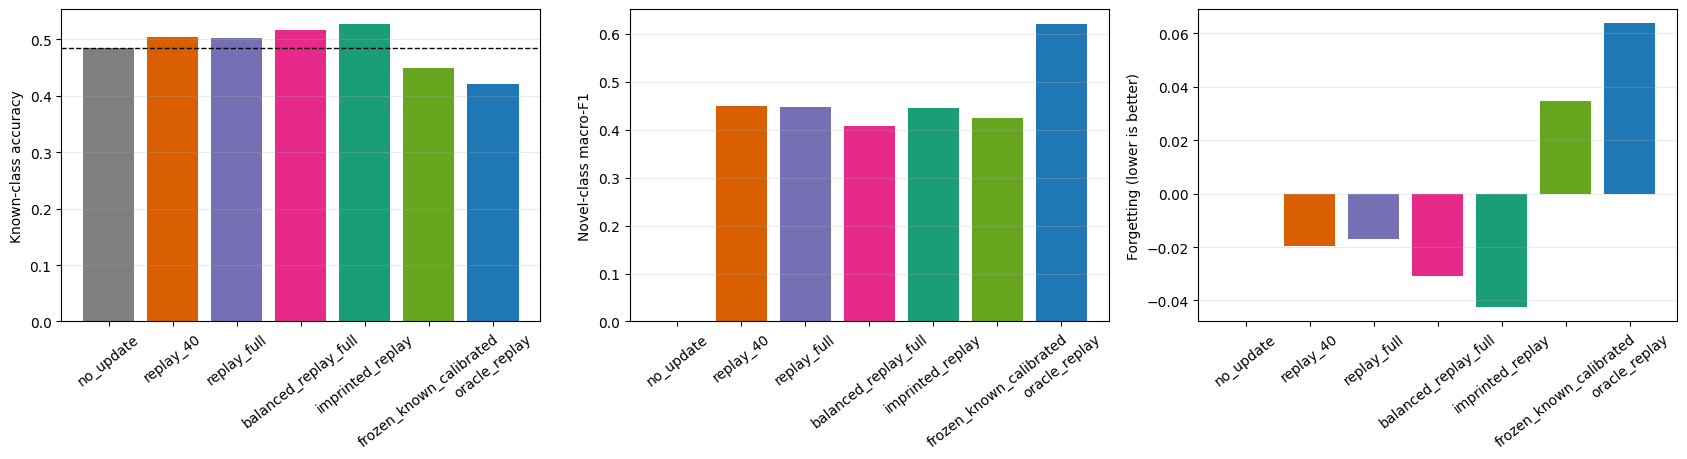

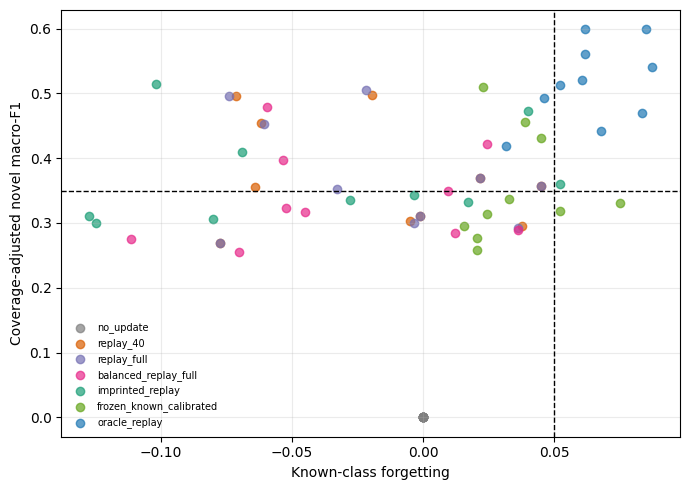

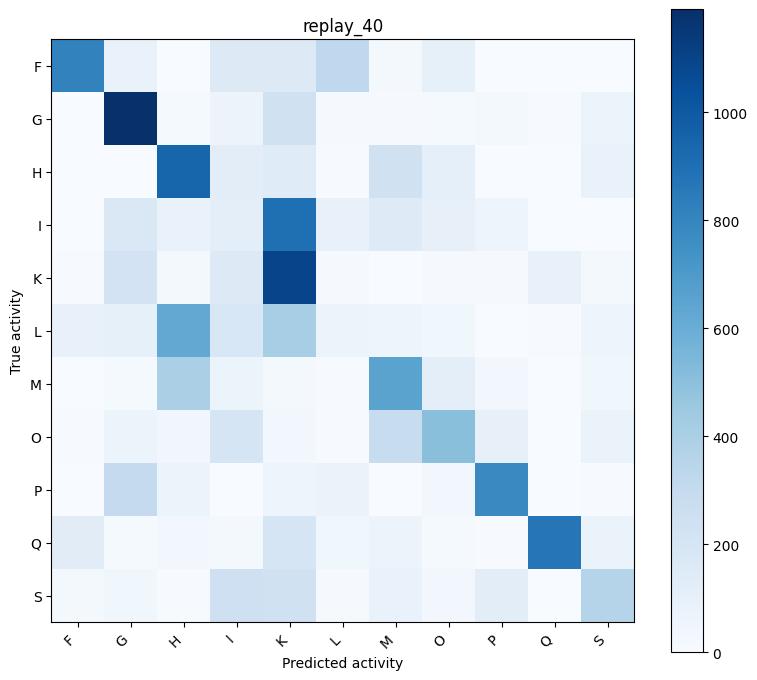

In [8]:
colors={'no_update':'#7f7f7f','replay_40':'#d95f02','replay_full':'#7570b3',
        'balanced_replay_full':'#e7298a','imprinted_replay':'#1b9e77',
        'frozen_known_calibrated':'#66a61e','oracle_replay':'#1f78b4'}
agg=results.groupby('method',as_index=False).agg(
    known_accuracy=('known_accuracy','mean'),novel_f1=('novel_macro_f1','mean'),
    coverage_adjusted=('coverage_adjusted_novel_f1','mean'),forgetting=('forgetting','mean'))
agg['order']=agg.method.map({m:i for i,m in enumerate(METHODS)});agg=agg.sort_values('order')
fig,axes=plt.subplots(1,3,figsize=(17,4.7))
axes[0].bar(agg.method,agg.known_accuracy,color=[colors[x] for x in agg.method])
axes[1].bar(agg.method,agg.novel_f1,color=[colors[x] for x in agg.method])
axes[2].bar(agg.method,agg.forgetting,color=[colors[x] for x in agg.method])
axes[0].axhline(BASE_KNOWN_ACCURACY,color='black',ls='--',lw=1)
axes[0].set_ylabel('Known-class accuracy');axes[1].set_ylabel('Novel-class macro-F1')
axes[2].set_ylabel('Forgetting (lower is better)')
for ax in axes:ax.tick_params(axis='x',rotation=38);ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig(OUT/'phase1c_method_comparison.png',dpi=180,bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(7,5))
for method in METHODS:
    q=results[results.method==method]
    ax.scatter(q.forgetting,q.coverage_adjusted_novel_f1,label=method,color=colors[method],alpha=.7)
ax.axvline(CFG.max_known_accuracy_drop,color='black',ls='--',lw=1)
ax.axhline(CFG.minimum_coverage_adjusted_novel_f1,color='black',ls='--',lw=1)
ax.set_xlabel('Known-class forgetting');ax.set_ylabel('Coverage-adjusted novel macro-F1')
ax.grid(alpha=.25);ax.legend(frameon=False,fontsize=7);fig.tight_layout()
fig.savefig(OUT/'phase1c_stability_plasticity.png',dpi=180,bbox_inches='tight');plt.show()

if SELECTED_METHOD:
    q=confusions[confusions.method==SELECTED_METHOD].groupby(
        ['true_activity','predicted_activity'],as_index=False)['count'].sum()
    labels=list(CFG.known_activities)+list(CFG.novel_activities)
    matrix=np.zeros((len(labels),len(labels)),dtype=int);loc={x:i for i,x in enumerate(labels)}
    for row in q.itertuples():matrix[loc[row.true_activity],loc[row.predicted_activity]]=row.count
    fig,ax=plt.subplots(figsize=(8,7));im=ax.imshow(matrix,cmap='Blues')
    ax.set_xticks(range(len(labels)),labels,rotation=45,ha='right');ax.set_yticks(range(len(labels)),labels)
    ax.set_xlabel('Predicted activity');ax.set_ylabel('True activity');ax.set_title(SELECTED_METHOD)
    fig.colorbar(im,ax=ax);fig.tight_layout()
    fig.savefig(OUT/'phase1c_selected_confusion.png',dpi=180,bbox_inches='tight');plt.show()


## Locked decision gates

The selected non-oracle method must satisfy the stability constraint in both arrival modes and then pass the same learning-quality thresholds that Phase 1B missed. Failure ends integration-method tuning and triggers encoder redesign.


In [9]:
if SELECTED_METHOD:
    target=results[results.method==SELECTED_METHOD]
    arrival=target.groupby('arrival_mode').agg(
        vocabulary_coverage=('vocabulary_coverage','mean'),known_accuracy=('known_accuracy','mean'),
        novel_macro_f1=('novel_macro_f1','mean'),coverage_adjusted_novel_f1=('coverage_adjusted_novel_f1','mean'),
        forgetting=('forgetting','mean'),overall_macro_f1=('overall_macro_f1','mean')).to_dict('index')
else:arrival={}

gates={
 'G1_disjoint_integration_and_evaluation_clients':not bool(set(CFG.integration_subjects)&set(CFG.evaluation_subjects)),
 'G2_dual_confirmation_only':bool((admissions.single_client_promotions==0).all()),
 'G3_method_selected_under_locked_rule':SELECTED_METHOD is not None,
 'G4_vocabulary_coverage_each_arrival':bool(arrival and all(v['vocabulary_coverage']>=CFG.minimum_vocabulary_coverage for v in arrival.values())),
 'G5_known_accuracy_drop_each_arrival':bool(arrival and all(v['forgetting']<=CFG.max_known_accuracy_drop for v in arrival.values())),
 'G6_novel_macro_f1_each_arrival':bool(arrival and all(v['novel_macro_f1']>=CFG.minimum_novel_macro_f1 for v in arrival.values())),
 'G7_coverage_adjusted_novel_f1_each_arrival':bool(arrival and all(v['coverage_adjusted_novel_f1']>=CFG.minimum_coverage_adjusted_novel_f1 for v in arrival.values())),
 'G8_full_fragment_gain_over_replay40':bool(SELECTED_METHOD!='replay_40' and arrival and all(
    results[(results.method==SELECTED_METHOD)&(results.arrival_mode==m)].coverage_adjusted_novel_f1.mean()>
    results[(results.method=='replay_40')&(results.arrival_mode==m)].coverage_adjusted_novel_f1.mean()
    for m in CFG.arrival_modes)),
 'G9_auditability':bool(len(events)>0 and len(admissions)>0 and len(results)>0 and len(per_class)>0)
}
decision={'phase':'Phase 1C','base_known_accuracy':BASE_KNOWN_ACCURACY,'base_known_macro_f1':BASE_KNOWN_F1,
          'selected_method':SELECTED_METHOD,'eligible_methods':eligible,'arrival_results':arrival,
          'gates':gates,'proceed_to_full_experiments':bool(all(gates.values())),
          'inheritance_enabled':False,
          'selection_rule':'Known accuracy loss <=0.05 in each arrival mode, then highest mean coverage-adjusted novel macro-F1.',
          'config':asdict(CFG)}
(OUT/'phase1c_decision.json').write_text(json.dumps(decision,indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 1C",
  "base_known_accuracy": 0.48484848484848486,
  "base_known_macro_f1": 0.461749455151776,
  "selected_method": "replay_40",
  "eligible_methods": [
    "replay_40",
    "replay_full",
    "balanced_replay_full",
    "imprinted_replay",
    "frozen_known_calibrated"
  ],
  "arrival_results": {
    "staggered": {
      "vocabulary_coverage": 0.8666666666666668,
      "known_accuracy": 0.4921212121212122,
      "novel_macro_f1": 0.4560464687284971,
      "coverage_adjusted_novel_f1": 0.39236975643814775,
      "forgetting": -0.007272727272727264,
      "overall_macro_f1": 0.42286578699747357
    },
    "synchronous": {
      "vocabulary_coverage": 0.8,
      "known_accuracy": 0.5168484848484848,
      "novel_macro_f1": 0.4413006259855905,
      "coverage_adjusted_novel_f1": 0.3495563694492727,
      "forgetting": -0.03199999999999997,
      "overall_macro_f1": 0.4268682351393712
    }
  },
  "gates": {
    "G1_disjoint_integration_and_evaluation_clients": true,
  

In [10]:
report=f"""# FedVocabHAR Phase 1C Decision Report

## Decision

**Selected method:** {SELECTED_METHOD}

**Proceed to full experiments:** {decision['proceed_to_full_experiments']}

**Inheritance enabled:** False

## Base model

- Known-class accuracy: {BASE_KNOWN_ACCURACY:.4f}
- Known-class macro-F1: {BASE_KNOWN_F1:.4f}

## Selected-method results

{json.dumps(arrival,indent=2)}

## Gates

"""
for name,value in gates.items():report+=f'- {name}: **{value}**\n'
report+="""

Complete windows were used only within directly confirmed local fragments. No report inherited a semantic label from another report or client. Evaluation clients remained fully held out.
"""
(OUT/'FedVocabHAR_Phase1C_Decision_Report.md').write_text(report)
print(report);print('saved outputs to',OUT)


# FedVocabHAR Phase 1C Decision Report

## Decision

**Selected method:** replay_40

**Proceed to full experiments:** False

**Inheritance enabled:** False

## Base model

- Known-class accuracy: 0.4848
- Known-class macro-F1: 0.4617

## Selected-method results

{
  "staggered": {
    "vocabulary_coverage": 0.8666666666666668,
    "known_accuracy": 0.4921212121212122,
    "novel_macro_f1": 0.4560464687284971,
    "coverage_adjusted_novel_f1": 0.39236975643814775,
    "forgetting": -0.007272727272727264,
    "overall_macro_f1": 0.42286578699747357
  },
  "synchronous": {
    "vocabulary_coverage": 0.8,
    "known_accuracy": 0.5168484848484848,
    "novel_macro_f1": 0.4413006259855905,
    "coverage_adjusted_novel_f1": 0.3495563694492727,
    "forgetting": -0.03199999999999997,
    "overall_macro_f1": 0.4268682351393712
  }
}

## Gates

- G1_disjoint_integration_and_evaluation_clients: **True**
- G2_dual_confirmation_only: **True**
- G3_method_selected_under_locked_rule: **True**
- G4_vo

## Interpretation

- If all gates pass, freeze the selected direct-only integration method and expand to full baselines and additional datasets.
- If the full-fragment methods improve novel recognition but remain below a gate, inspect the saved per-class metrics and confusion matrix before changing the model.
- If the oracle remains strong while all direct methods fail, confirmed-data efficiency remains the bottleneck.
- If the oracle is also weak or base accuracy remains inadequate, stop integration tuning and redesign the representation.
